# PathSnap — 05 · HMM and Viterbi Route Reconstruction (stage 7)

Results come from `scripts/hmm_decode.py`; the decoder itself is in `src/hmm.py`. This notebook reads `outputs/hmm/` and builds
the tables, figures and Folium maps.

Classifier-only matching picks each point's best arc on its own, so two consecutive points can land on roads that are not
connected. The HMM adds the road network and the time order of the points.

### 1. Hidden states
At GPS observation *t*, the hidden state is the candidate arc the vehicle is on. There is one state per candidate from stage 3
(radius 50 m, at most 12 arcs, with fallback widening), so every observation has at least one state. Each state keeps its
`arc_id`, so a decoded state *is* a road segment.

### 2. Emission scores
$e_t(c) = w \cdot \log \max(p_t(c), 10^{-4})$, where $p_t(c)$ is the **tuned HistGradientBoosting** probability that candidate *c*
is the true arc. The classifier posterior replaces the likelihood: this is a hybrid HMM with a uniform prior over candidates.
The floor stops one overconfident zero from vetoing a state, and *w* sets how far the classifier is trusted relative to the
road network. Stage 4 chose the model partly on **log loss** because these probabilities are used directly here.

### 3. Transition scores (Newson & Krumm style)
For candidate *i* at *t-1* and *j* at *t*, `route_d` is the driving distance through the directed road graph from the projection of
point *t-1* on arc *i* to the projection of point *t* on arc *j*:
- same arc, forward (or backward by at most 8 m of GPS jitter): $|f_j - f_i| \cdot L$
- otherwise: $(1-f_i)L_i + \text{shortest path}(\text{to}(i), \text{from}(j)) + f_j L_j$, computed with a distance-bounded Dijkstra and cached per source node

$T(i,j) = -\,|\text{route\_d} - \text{gc}| / \beta \; - \; \text{uturn\_cost}\cdot[\,j \text{ is the reverse twin of } i\,]$, where gc is
the straight-line distance between the two GPS fixes. A real vehicle drives about as far as the fixes moved, so pairs that
need a detour are unlikely. One-way streets are respected because the graph is directed.

### 4. Missing candidates, invalid transitions and GPS gaps
- **Missing candidates:** fallback widening (200 m, then 1 km, then the nearest arc) means no observation is ever without a state.
- **Invalid transition** (no path within $\max(3\,\text{gc}+200, 400)$ m, capped at 8 km): instead of $-\infty$ it gets the finite score
  $-\text{break\_cost}$, so Viterbi never dead-ends. If every pair in a step is invalid, the chain effectively restarts from the best emission.
- **GPS gaps** longer than `gap_s`: the transition is flat (0), so the two sides are decoded independently. This avoids forcing a
  made-up connection across a long gap.

### 5. Viterbi recurrence
$\delta_1(c) = e_1(c)$, $\quad \delta_t(j) = e_t(j) + \max_i\,[\delta_{t-1}(i) + T_t(i,j)]$, $\quad \psi_t(j) = \arg\max_i[\cdot]$,
then backtrack from $\arg\max_c \delta_N(c)$. This costs $O(NK^2)$ per trip. Scores are re-centred every step to avoid underflow.
The decoded arcs are then joined by shortest paths into one **connected route** (`reconstruct_route`).

### Protocol (no leakage)
- **Decoder tuning:** decoder parameters are tuned with Optuna TPE on **out-of-fold** train probabilities. The tuned HGB is refit on
  4 of 5 GroupKFold folds and scores the held-out trips, so the probabilities are as honest as at test time.
- **student_test:** decoded **once** with the final parameters, using the stage-6 refit model.

In [1]:
import os, sys, json, warnings
sys.path.insert(0, os.path.abspath('..')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_io import Trip
from src.hmm import RoadNetwork, reconstruct_route, route_overlap
from src.viz import trip_map, COLORS
RES = '../outputs/hmm'; FIG = f'{RES}/figures'; MAPS = f'{RES}/maps'
os.makedirs(FIG, exist_ok=True); os.makedirs(MAPS, exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 220)
def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG}/{name}.png', dpi=150, bbox_inches='tight'); plt.show()
cfg = json.load(open(f'{RES}/hmm_config.json'))
comp = pd.read_csv(f'{RES}/comparison.csv', index_col=0)
pt = pd.read_csv(f'{RES}/per_trip_results.csv', dtype={'trip': str})
dec = pd.read_parquet(f'{RES}/student_test_decoded.parquet')
trials = pd.read_csv(f'{RES}/decoder_trials.csv')
print('classifier:', cfg['classifier'])
print('tuned decoder parameters:', {k: round(v, 3) for k, v in cfg['hmm_params'].items()})
print('defaults:', cfg['default_params'])

classifier: HistGradientBoosting (tuned, stage 6)
tuned decoder parameters: {'emission_weight': 0.547, 'beta': 23.312, 'break_cost': 4.713, 'uturn_cost': 29.103, 'gap_s': 41.678, 'prob_floor': 0.0}
defaults: {'emission_weight': 1.0, 'beta': 20.0, 'break_cost': 30.0, 'uturn_cost': 2.0, 'gap_s': 60.0, 'prob_floor': 0.0001}


## 6. Decoder parameter search (train out-of-fold only)

objective: point-level Top-1 accuracy on train out-of-fold probabilities (78 reliable trips)
sampler: TPE(seed=42, 12 startup), trials: 60, search time: 1.7 min
search space: {'emission_weight': 'log-uniform 0.1-5', 'beta': 'log-uniform 2-200 m', 'break_cost': 'log-uniform 0.5-200 (widened from 5-200: first search hit 5)', 'uturn_cost': 'uniform 0-30 (widened from 0-10: first search hit 9.2)', 'gap_s': 'log-uniform 10-600 s'}
best train-OOF Top-1: 0.9167; per fold: [0.8716, 0.9335, 0.9567, 0.9082, 0.9159]


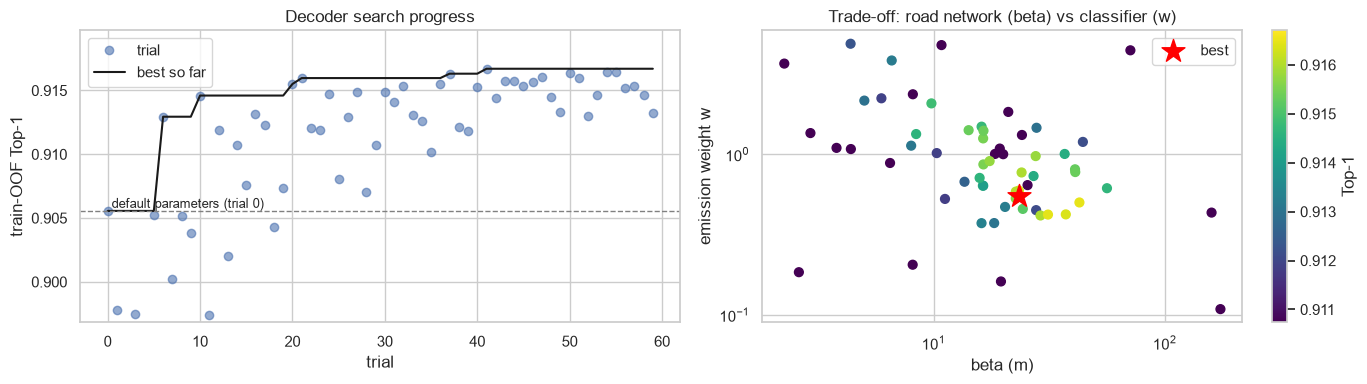

,number,value,params_beta,params_break_cost,params_emission_weight,params_gap_s,params_uturn_cost
41,41,0.9167,23.3116,4.7127,0.5472,41.6777,29.1025
55,55,0.9165,42.7383,5.6965,0.5005,20.0538,25.8493
54,54,0.9165,31.2475,4.6457,0.4207,24.5353,25.8528
50,50,0.9164,37.3201,5.1544,0.4218,30.6285,26.7609
37,37,0.9163,23.3924,5.8913,0.5934,24.6653,28.4101
47,47,0.9160,22.6776,5.5140,0.5845,31.4311,26.3438
51,51,0.9160,29.0039,6.6025,0.4153,21.2915,26.6356
21,21,0.9160,24.0233,12.0249,0.7697,24.9645,29.7946


In [2]:
s = cfg['search']
print(f"objective: {s['objective']}"); print(f"sampler: {s['sampler']}, trials: {s['n_trials']}, search time: {s['search_seconds']/60:.1f} min")
print('search space:', s['space'])
print(f"best train-OOF Top-1: {s['best_value']:.4f}; per fold: {np.round(s['best_fold_top1'], 4).tolist()}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(trials.number, trials.value, 'o', alpha=.6, label='trial'); ax[0].plot(trials.number, trials.value.cummax(), c='k', label='best so far')
ax[0].axhline(trials.value.iloc[0], ls='--', c='grey', lw=1); ax[0].text(0, trials.value.iloc[0], ' default parameters (trial 0)', va='bottom', fontsize=9)
ax[0].set_xlabel('trial'); ax[0].set_ylabel('train-OOF Top-1'); ax[0].set_title('Decoder search progress'); ax[0].legend()
ax[0].set_ylim(trials.value.quantile(0.1) - 0.005, trials.value.max() + 0.003)
top = trials.nlargest(15, 'value')
sc = ax[1].scatter(trials.params_beta, trials.params_emission_weight, c=trials.value, cmap='viridis',
                   vmin=trials.value.quantile(0.3), s=40)
ax[1].scatter(top.params_beta.iloc[:1], top.params_emission_weight.iloc[:1], marker='*', s=300, c='red', label='best')
ax[1].set_xscale('log'); ax[1].set_yscale('log'); ax[1].set_xlabel('beta (m)'); ax[1].set_ylabel('emission weight w')
ax[1].set_title('Trade-off: road network (beta) vs classifier (w)'); ax[1].legend(); plt.colorbar(sc, ax=ax[1], label='Top-1')
savefig('01_decoder_search')
trials.sort_values('value', ascending=False).head(8).filter(regex='number|value|params_').round(4)

Only the ratio matters to first order: a transition costs $|\Delta|/\beta$ against an emission of $w\log p$. A small $\beta\,w$ lets
the network overrule the classifier; a large one gives back classifier-only matching. The good region is a diagonal band in the
right-hand plot, not a single point.

## 7. Classifier-only vs classifier + HMM (report section 5)

In [3]:
METH = ['classifier_only', 'hmm_geometric_emission', 'hmm_default_params', 'hmm_tuned']
NAMES = {'classifier_only': 'Classifier only (tuned HGB, argmax)', 'hmm_geometric_emission': 'HMM, distance emission (no classifier)',
         'hmm_default_params': 'HGB + HMM (default parameters)', 'hmm_tuned': 'HGB + HMM (tuned parameters)'}
cols = ['top1_accuracy', 'route_continuity', 'network_connectivity', 'route_precision', 'route_recall', 'route_f1',
        'unjoinable_transitions', 'decode_ms_per_1k_points']
tabs = {}
for part in ['student_test', 'train_oof']:
    t = comp.loc[[f'{part}/{m}' for m in METH], cols]; t.index = [NAMES[m] for m in METH]; tabs[part] = t
    t.to_csv(f'{RES}/comparison_{part}.csv')
print('student_test (10 trips, decoded once):')
tabs['student_test'].style.format(precision=4).background_gradient(subset=['top1_accuracy', 'route_f1'], cmap='Greens')

student_test (10 trips, decoded once):


,top1_accuracy,route_continuity,network_connectivity,route_precision,route_recall,route_f1,unjoinable_transitions,decode_ms_per_1k_points
"Classifier only (tuned HGB, argmax)",0.8814,0.9685,0.9855,0.7023,0.9984,0.8179,80.0000,0.0247
"HMM, distance emission (no classifier)",0.9076,0.9927,0.9969,0.8757,0.9970,0.9304,7.0000,9.5555
HGB + HMM (default parameters),0.9158,0.9956,0.9994,0.9435,0.9974,0.9690,3.0000,9.3276
HGB + HMM (tuned parameters),0.9261,0.9948,0.9982,0.9298,0.9978,0.9619,3.0000,9.3964


In [4]:
print('train out-of-fold (78 reliable trips, where the decoder was tuned):')
tabs['train_oof'].style.format(precision=4).background_gradient(subset=['top1_accuracy', 'route_f1'], cmap='Greens')

train out-of-fold (78 reliable trips, where the decoder was tuned):


,top1_accuracy,route_continuity,network_connectivity,route_precision,route_recall,route_f1,unjoinable_transitions,decode_ms_per_1k_points
"Classifier only (tuned HGB, argmax)",0.8582,0.9676,0.9806,0.6266,0.9960,0.7480,1070.0000,0.0006
"HMM, distance emission (no classifier)",0.9054,0.9884,0.9886,0.7667,0.9929,0.8514,321.0000,10.7763
HGB + HMM (default parameters),0.9056,0.9934,0.9958,0.8759,0.9918,0.9225,102.0000,9.5739
HGB + HMM (tuned parameters),0.9167,0.9924,0.9929,0.8378,0.9935,0.8984,119.0000,9.1838


**Metrics**
- **Top-1 accuracy (point level):** share of GPS observations whose decoded arc is the reference arc.
- **Route continuity:** share of consecutive observations whose arcs are the same, adjacent, two hops apart, or a u-turn twin.
  This is the strict definition used in stages 4–6.
- **Network connectivity:** share of consecutive observations whose arcs are reachable in the directed graph within the search
  limit (excluding split gaps).
- **Route precision / recall / F1 (sequence level):** the decoded arcs are joined by shortest paths into a full route, then compared
  with `.route` as length-weighted arc sets. Precision is the share of the predicted route's length that is really driven; recall is
  the share of the reference route that is recovered.

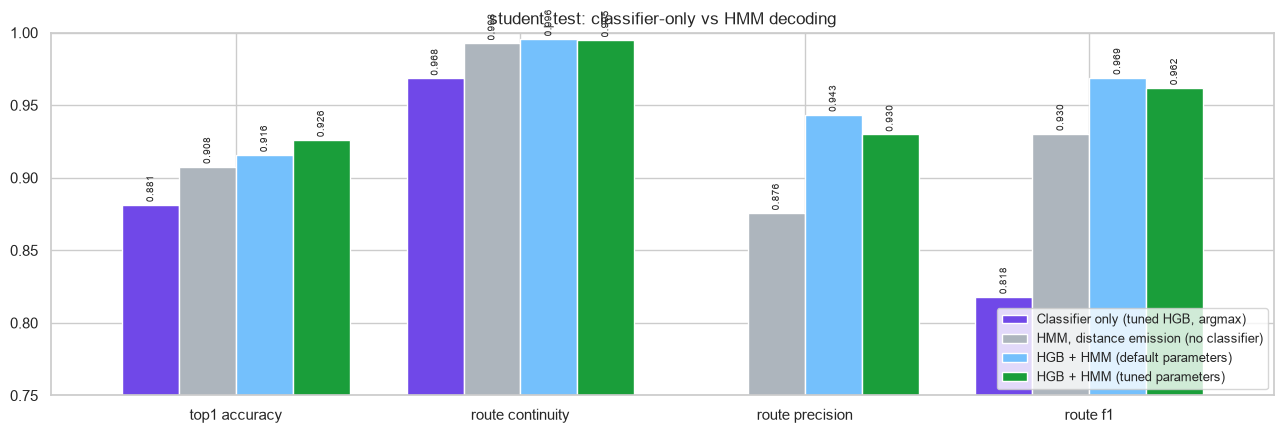

In [5]:
st = tabs['student_test']
plot = st[['top1_accuracy', 'route_continuity', 'route_precision', 'route_f1']].rename(columns=lambda c: c.replace('_', ' '))
ax = plot.T.plot.bar(figsize=(13, 4.5), rot=0, color=['#7048e8', '#adb5bd', '#74c0fc', '#1a9e3a'], width=0.8)
ax.set_ylim(0.75, 1.0); ax.set_title('student_test: classifier-only vs HMM decoding'); ax.legend(loc='lower right', fontsize=9)
for c in ax.containers: ax.bar_label(c, fmt='%.3f', fontsize=7, rotation=90, padding=2)
savefig('02_classifier_vs_hmm')

## 8. Per-trip results: where the HMM helps and where it does not

In [6]:
p = pt[pt.partition == 'student_test'].pivot(index='trip', columns='method', values=['top1_accuracy', 'route_f1', 'route_continuity'])
per = pd.DataFrame({'points': pt[(pt.partition == 'student_test') & (pt.method == 'hmm_tuned')].set_index('trip').n_points,
                    'top1_classifier': p['top1_accuracy']['classifier_only'], 'top1_hmm': p['top1_accuracy']['hmm_tuned'],
                    'continuity_classifier': p['route_continuity']['classifier_only'], 'continuity_hmm': p['route_continuity']['hmm_tuned'],
                    'route_f1_classifier': p['route_f1']['classifier_only'], 'route_f1_hmm': p['route_f1']['hmm_tuned']})
per['top1_gain'] = per.top1_hmm - per.top1_classifier
per.to_csv(f'{RES}/per_trip_student_test.csv')
per.sort_values('top1_gain').style.format(precision=4).background_gradient(subset=['top1_gain'], cmap='RdYlGn', vmin=-0.05, vmax=0.05)

,points,top1_classifier,top1_hmm,continuity_classifier,continuity_hmm,route_f1_classifier,route_f1_hmm,top1_gain
trip,,,,,,,,
00000007,1354,0.9136,0.9165,1.0000,0.9970,0.9853,0.9765,0.0030
00000000,2503,0.9469,0.9569,0.9848,0.9976,0.9306,0.9925,0.0100
00000052,262,0.9695,0.9809,0.9808,0.9923,0.7682,0.8260,0.0115
00000040,2995,0.9472,0.9726,0.9893,0.9993,0.8550,0.9996,0.0254
00000065,768,0.8294,0.8698,0.9648,0.9961,0.6769,0.9562,0.0404
00000009,1049,0.8761,0.9190,0.9475,0.9905,0.8193,0.9671,0.0429
00000076,1486,0.9004,0.9482,0.9468,0.9892,0.6997,0.9247,0.0478
00000091,874,0.8856,0.9336,0.9393,0.9851,0.6321,0.9612,0.0481
00000056,3958,0.9025,0.9603,0.9401,0.9939,0.8149,0.9438,0.0579


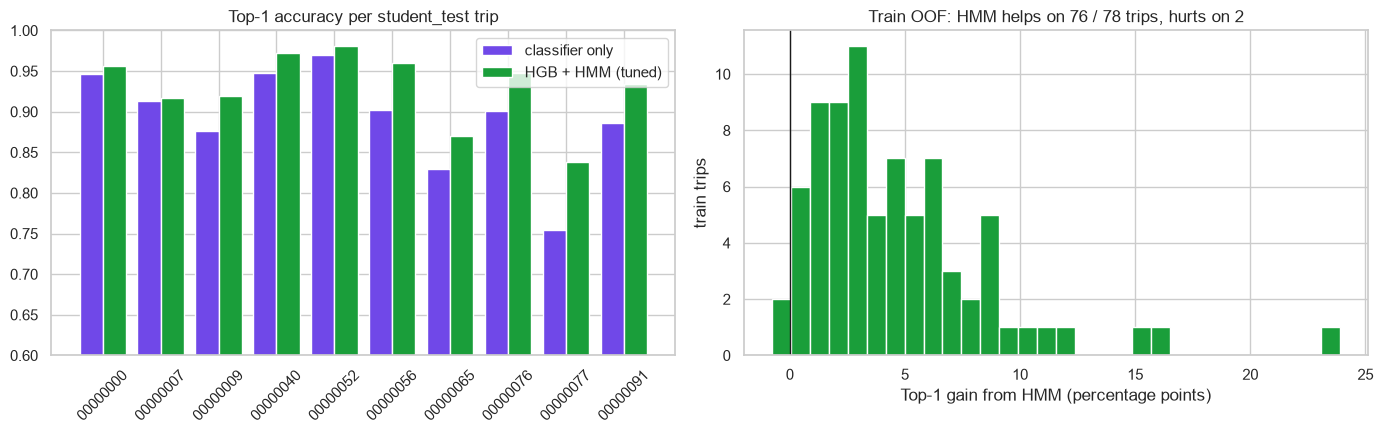

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(per)); w = 0.4
ax[0].bar(x - w/2, per.top1_classifier, w, label='classifier only', color='#7048e8')
ax[0].bar(x + w/2, per.top1_hmm, w, label='HGB + HMM (tuned)', color='#1a9e3a')
ax[0].set_xticks(x); ax[0].set_xticklabels(per.index, rotation=45); ax[0].set_ylim(0.6, 1); ax[0].legend(); ax[0].set_title('Top-1 accuracy per student_test trip')
tr = pt[(pt.partition == 'train_oof')].pivot(index='trip', columns='method', values='top1_accuracy')
gain = tr.hmm_tuned - tr.classifier_only
ax[1].hist(gain * 100, bins=30, color='#1a9e3a'); ax[1].axvline(0, c='k', lw=1)
ax[1].set_xlabel('Top-1 gain from HMM (percentage points)'); ax[1].set_ylabel('train trips')
ax[1].set_title(f'Train OOF: HMM helps on {(gain > 0).sum()} / {len(gain)} trips, hurts on {(gain < 0).sum()}')
savefig('03_per_trip_gain')

flip
both right       16533
fixed by HMM      1211
both wrong        1062
broken by HMM      354



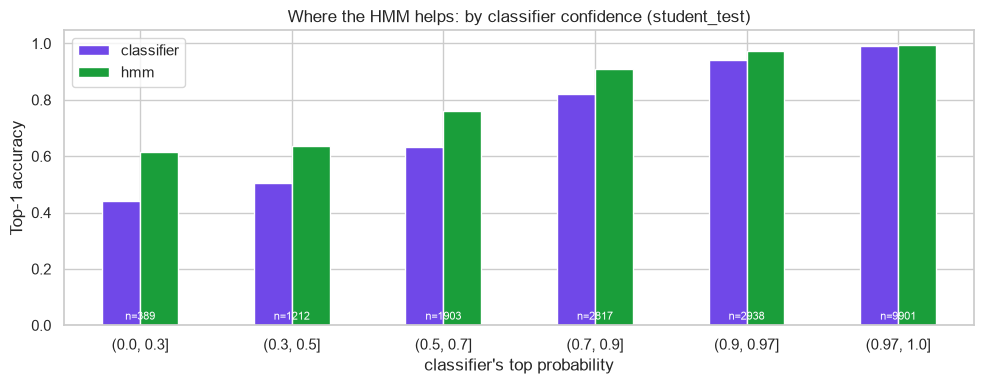

,points,classifier,hmm,gain
conf_bin,,,,
"(0.0, 0.3]",389,0.4396,0.6144,0.1748
"(0.3, 0.5]",1212,0.5033,0.6378,0.1345
"(0.5, 0.7]",1903,0.6316,0.7604,0.1287
"(0.7, 0.9]",2817,0.8214,0.9098,0.0884
"(0.9, 0.97]",2938,0.9398,0.9724,0.0327
"(0.97, 1.0]",9901,0.9927,0.9964,0.0036


In [8]:
dec['flip'] = np.select([(dec.correct_classifier == 0) & (dec.correct_hmm == 1), (dec.correct_classifier == 1) & (dec.correct_hmm == 0),
                         (dec.correct_classifier == 1) & (dec.correct_hmm == 1)], ['fixed by HMM', 'broken by HMM', 'both right'], 'both wrong')
print(dec.flip.value_counts().to_string()); print()
dec['conf_bin'] = pd.cut(dec.prob_classifier, [0, .3, .5, .7, .9, .97, 1.0])
by = dec.groupby('conf_bin', observed=True).agg(points=('flip', 'size'), classifier=('correct_classifier', 'mean'), hmm=('correct_hmm', 'mean'))
by['gain'] = by.hmm - by.classifier
fig, ax = plt.subplots(figsize=(10, 4))
by[['classifier', 'hmm']].plot.bar(ax=ax, color=['#7048e8', '#1a9e3a'], rot=0)
for i, n in enumerate(by.points): ax.text(i, 0.02, f'n={n}', ha='center', fontsize=8, color='white')
ax.set_xlabel("classifier's top probability"); ax.set_ylabel('Top-1 accuracy'); ax.set_title('Where the HMM helps: by classifier confidence (student_test)')
savefig('04_gain_by_confidence')
by.round(4)

The gain is concentrated where the classifier is **unsure**. These are mostly points near junctions, parallel roads and twin
(two-way) arcs, where the road network decides the answer. When the classifier is very confident, the HMM rarely changes anything.

Cases where the HMM **does not help** (the "broken by HMM" points and the trips with negative gain):
- **Reference label noise:** the ground-truth arc comes from aligning points to `.route`. Near junctions the HMM picks the
  connected arc, while the label may sit on the neighbouring arc for a point or two.
- **Short arcs crossed in under 1 s:** the HMM can choose a slightly earlier or later arc of the same connected route.
  That counts as a point error but costs nothing at route level, which is why route precision moves less than Top-1.
- **Wrong long stretches:** if the classifier is confidently wrong for many consecutive points on a parallel road (for example a
  service road beside a highway), both readings are connected and the HMM keeps the wrong one.

## 9. Folium maps: classifier-only vs HMM route

In [9]:
def route_for(tid, col):
    d = dec[dec.trip == tid].sort_values('point_idx')
    net = RoadNetwork(Trip(tid, 'student_test'))
    return reconstruct_route(net, d[col].to_numpy())[0], d

def compare_map(tid):
    trip = Trip(tid, 'student_test')
    r_clf, d = route_for(tid, 'arc_classifier'); r_hmm, _ = route_for(tid, 'arc_hmm')
    m = trip_map(trip, routes={'Classifier-only route': (r_clf, COLORS['classifier']), 'HGB + HMM route': (r_hmm, COLORS['predicted'])},
                 wrong_points={'Points wrong after HMM': (d.point_idx[d.correct_hmm == 0].to_numpy(), COLORS['wrong'])})
    m.save(f'{MAPS}/trip_{tid}_classifier_vs_hmm.html'); return m

best_trip = per.top1_gain.idxmax(); worst_trip = per.top1_gain.idxmin()
print('largest HMM gain:', best_trip, round(per.loc[best_trip, 'top1_gain'], 4), '| smallest gain:', worst_trip, round(per.loc[worst_trip, 'top1_gain'], 4))
compare_map(best_trip)

largest HMM gain: 00000077 0.0846 | smallest gain: 00000007 0.003


In [10]:
compare_map(worst_trip)

In [11]:
for tid in per.index:
    if tid not in (best_trip, worst_trip): compare_map(tid)
print('maps saved:', sorted(os.listdir(MAPS)))

maps saved: ['trip_00000000_classifier_vs_hmm.html', 'trip_00000007_classifier_vs_hmm.html', 'trip_00000009_classifier_vs_hmm.html', 'trip_00000040_classifier_vs_hmm.html', 'trip_00000052_classifier_vs_hmm.html', 'trip_00000056_classifier_vs_hmm.html', 'trip_00000065_classifier_vs_hmm.html', 'trip_00000076_classifier_vs_hmm.html', 'trip_00000077_classifier_vs_hmm.html', 'trip_00000091_classifier_vs_hmm.html']


## 10. A zoomed example of the HMM fixing a disconnected classifier match

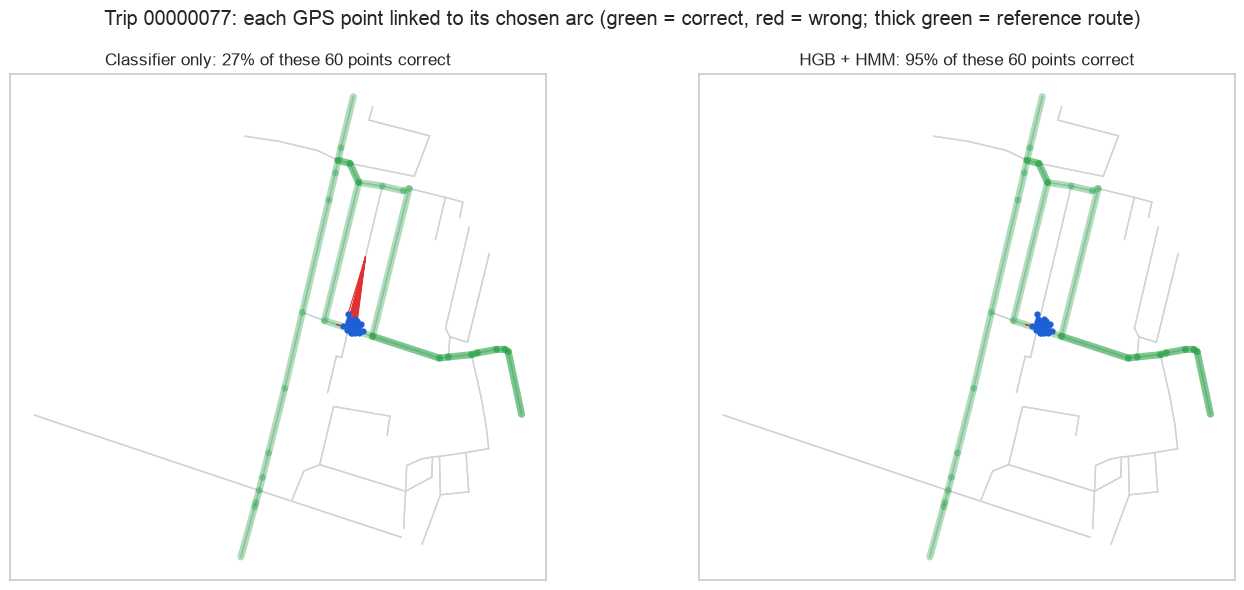

In [12]:
d = dec[dec.trip == best_trip].sort_values('point_idx').reset_index(drop=True)
trip = Trip(best_trip, 'student_test'); xy = trip.track_xy; A, B = trip.arc_xy
fixed = d.index[d.flip == 'fixed by HMM'].to_numpy()
# window with the most fixes
c = fixed[np.argmax([((fixed > f - 40) & (fixed < f + 40)).sum() for f in fixed])] if len(fixed) else len(d) // 2
w = d.iloc[max(c - 30, 0): c + 30]
fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
pts = xy[w.point_idx]
near = np.flatnonzero(np.minimum(np.linalg.norm(A - pts.mean(0), axis=1), np.linalg.norm(B - pts.mean(0), axis=1)) < 250)
for a, col, title in [(ax[0], 'arc_classifier', 'Classifier only'), (ax[1], 'arc_hmm', 'HGB + HMM')]:
    for k in near: a.plot([A[k, 0], B[k, 0]], [A[k, 1], B[k, 1]], c='#ced4da', lw=1, zorder=1)
    for k in np.unique(trip.route):
        if k in near: a.plot([A[k, 0], B[k, 0]], [A[k, 1], B[k, 1]], c=COLORS['reference'], lw=5, alpha=.35, zorder=2)
    ok = w[col.replace('arc', 'correct')].to_numpy() == 1
    for (i, arc), good in zip(w[['point_idx', col]].to_numpy(), ok):
        p = xy[i]; m = (A[arc] + B[arc]) / 2
        a.plot([p[0], m[0]], [p[1], m[1]], c='#1a9e3a' if good else COLORS['wrong'], lw=.8, zorder=3)
    a.scatter(pts[:, 0], pts[:, 1], c=COLORS['gps'], s=12, zorder=4)
    a.set_title(f'{title}: {ok.mean():.0%} of these {len(w)} points correct'); a.set_aspect('equal'); a.set_xticks([]); a.set_yticks([])
fig.suptitle(f'Trip {best_trip}: each GPS point linked to its chosen arc (green = correct, red = wrong; thick green = reference route)')
savefig('05_zoomed_example')

In this window (trip 00000077) the vehicle is **standing still near a junction**: about 60 fixes jitter within a few metres.
For most of them (only 27% correct) the classifier picks the short side street running north, because those fixes are
close to it and the heading is unreliable when the vehicle is not moving. A real vehicle cannot hop back and forth between two arcs every second, so the
transition scores keep the HMM on one connected arc, and it gets 95% of these 60 points right.

## 11. Summary
- The tuned decoder is the final stage-7 configuration. It is saved in `outputs/hmm/hmm_config.json` and stage 8 exports it with the model.
- Report tables: `comparison_student_test.csv`, `comparison_train_oof.csv` and `per_trip_student_test.csv`.
- Maps: `outputs/hmm/maps/`. Each has the reference route, the classifier-only route, the HMM route, raw GPS, the road network
  and a toggleable layer of wrongly matched points.